# 🔍 Viral-Lens: Phase 2 — Exploratory Data Analysis & Quality Audit

This notebook investigates the raw dataset for **Viral-Lens**, a multimodal deep learning system that predicts YouTube video virality.

### Objectives:
1. Load `train.csv` and `test.csv` and examine shapes, schemas, null values, and identifier uniqueness.
2. Formally verify the virality score mathematical relationship:
   $$\text{virality\_score} \approx \ln(\text{view\_count} + 1) - \ln(\text{subscriber\_count} + 1)$$
3. Analyze statistical distributions of raw and log-scaled variables (`view_count`, `subscriber_count`, `duration`).
4. Investigate temporal dynamics (`published_at`, upload hour, weekday, upload year).
5. Examine title length, multilingual content, and emoji presence.
6. Audit thumbnail URLs in preparation for Phase 3 image acquisition.
7. Document a formal **Data Quality Note** and cleaning decisions.


In [2]:
import os
import math
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from urllib.parse import urlparse

# Visualization styling
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['figure.figsize'] = (10, 5)
plt.rcParams['font.size'] = 11

print("Environment and libraries loaded successfully.")


Environment and libraries loaded successfully.


## 1. Load Data & Schema Overview

In [4]:
TRAIN_PATH = "../data/raw/train.csv"
TEST_PATH = "../data/raw/test.csv"

train_df = pd.read_csv(TRAIN_PATH)
test_df = pd.read_csv(TEST_PATH)

print(f"Train Dataset Shape: {train_df.shape[0]:,} rows x {train_df.shape[1]} columns")
print(f"Test Dataset Shape:  {test_df.shape[0]:,} rows x {test_df.shape[1]} columns")


Train Dataset Shape: 7,000 rows x 8 columns
Test Dataset Shape:  3,014 rows x 6 columns


In [5]:
summary_df = pd.DataFrame({
    'Train_Dtype': train_df.dtypes,
    'Train_Nulls': train_df.isnull().sum(),
    'Train_Null_%': (train_df.isnull().sum() / len(train_df)) * 100,
    'Train_Unique': train_df.nunique()
})
print("=== Train Dataset Schema & Missingness ===")
display(summary_df)

test_summary_df = pd.DataFrame({
    'Test_Dtype': test_df.dtypes,
    'Test_Nulls': test_df.isnull().sum(),
    'Test_Null_%': (test_df.isnull().sum() / len(test_df)) * 100,
    'Test_Unique': test_df.nunique()
})
print("\n=== Test Dataset Schema & Missingness ===")
display(test_summary_df)


=== Train Dataset Schema & Missingness ===
                 Train_Dtype  Train_Nulls  Train_Null_%  Train_Unique
video_id              object            0           0.0          7000
title                 object            0           0.0          6958
thumbnail_url         object            0           0.0          7000
published_at          object            0           0.0          6994
duration               int64            0           0.0          1555
view_count             int64            0           0.0          6994
subscriber_count       int64            0           0.0          2445
virality_score       float64            0           0.0          7000

=== Test Dataset Schema & Missingness ===
                 Test_Dtype  Test_Nulls  Test_Null_%  Test_Unique
video_id             object           0          0.0         3014
title                object           0          0.0         3006
thumbnail_url        object           0          0.0         3014
published_at        

### Identifier Integrity & Leakage Check
We check for duplicates in `video_id` within splits and verify that no `video_id` from the test set appears in the training set.

In [7]:
train_dups = train_df['video_id'].duplicated().sum()
test_dups = test_df['video_id'].duplicated().sum()
overlap = len(set(train_df['video_id']).intersection(set(test_df['video_id'])))

print(f"Duplicate video_ids in Train: {train_dups}")
print(f"Duplicate video_ids in Test:  {test_dups}")
print(f"Overlapping video_ids (Train vs Test): {overlap}")
assert train_dups == 0 and test_dups == 0 and overlap == 0, "Integrity check failed!"
print("Identifer integrity verified: All video_ids are unique with 0 train/test overlap.")


Duplicate video_ids in Train: 0
Duplicate video_ids in Test:  0
Overlapping video_ids (Train vs Test): 0
Identifer integrity verified: All video_ids are unique with 0 train/test overlap.


## 2. Mathematical Verification of Virality Score
The domain formula is:
$$\text{virality\_score} = \ln(\text{view\_count} + 1) - \ln(\text{subscriber\_count} + 1)$$
We verify this across all rows in `train.csv`.

Maximum absolute discrepancy: 1.33e-15
Mean absolute discrepancy:    5.72e-17
Rows with discrepancy > 1e-4: 0


<ipython-input-1-0d98586b218c>:16: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.show()


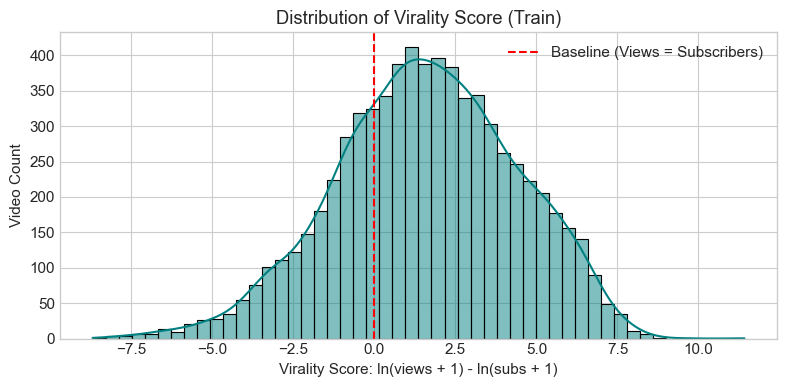

In [9]:
calculated_score = np.log(train_df['view_count'] + 1) - np.log(train_df['subscriber_count'] + 1)
score_discrepancy = (train_df['virality_score'] - calculated_score).abs()

print(f"Maximum absolute discrepancy: {score_discrepancy.max():.2e}")
print(f"Mean absolute discrepancy:    {score_discrepancy.mean():.2e}")
print(f"Rows with discrepancy > 1e-4: {(score_discrepancy > 1e-4).sum()}")

plt.figure(figsize=(8, 4))
sns.histplot(train_df['virality_score'], bins=50, kde=True, color='teal')
plt.title("Distribution of Virality Score (Train)")
plt.xlabel("Virality Score: ln(views + 1) - ln(subs + 1)")
plt.ylabel("Video Count")
plt.axvline(0, color='red', linestyle='--', label='Baseline (Views = Subscribers)')
plt.legend()
plt.tight_layout()
plt.show()


## 3. Distribution & Skewness Analysis
Because view counts and subscriber counts follow power-law distributions, we examine them on both raw and logarithmic scales.

<ipython-input-1-3154cc0a53a1>:22: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.show()


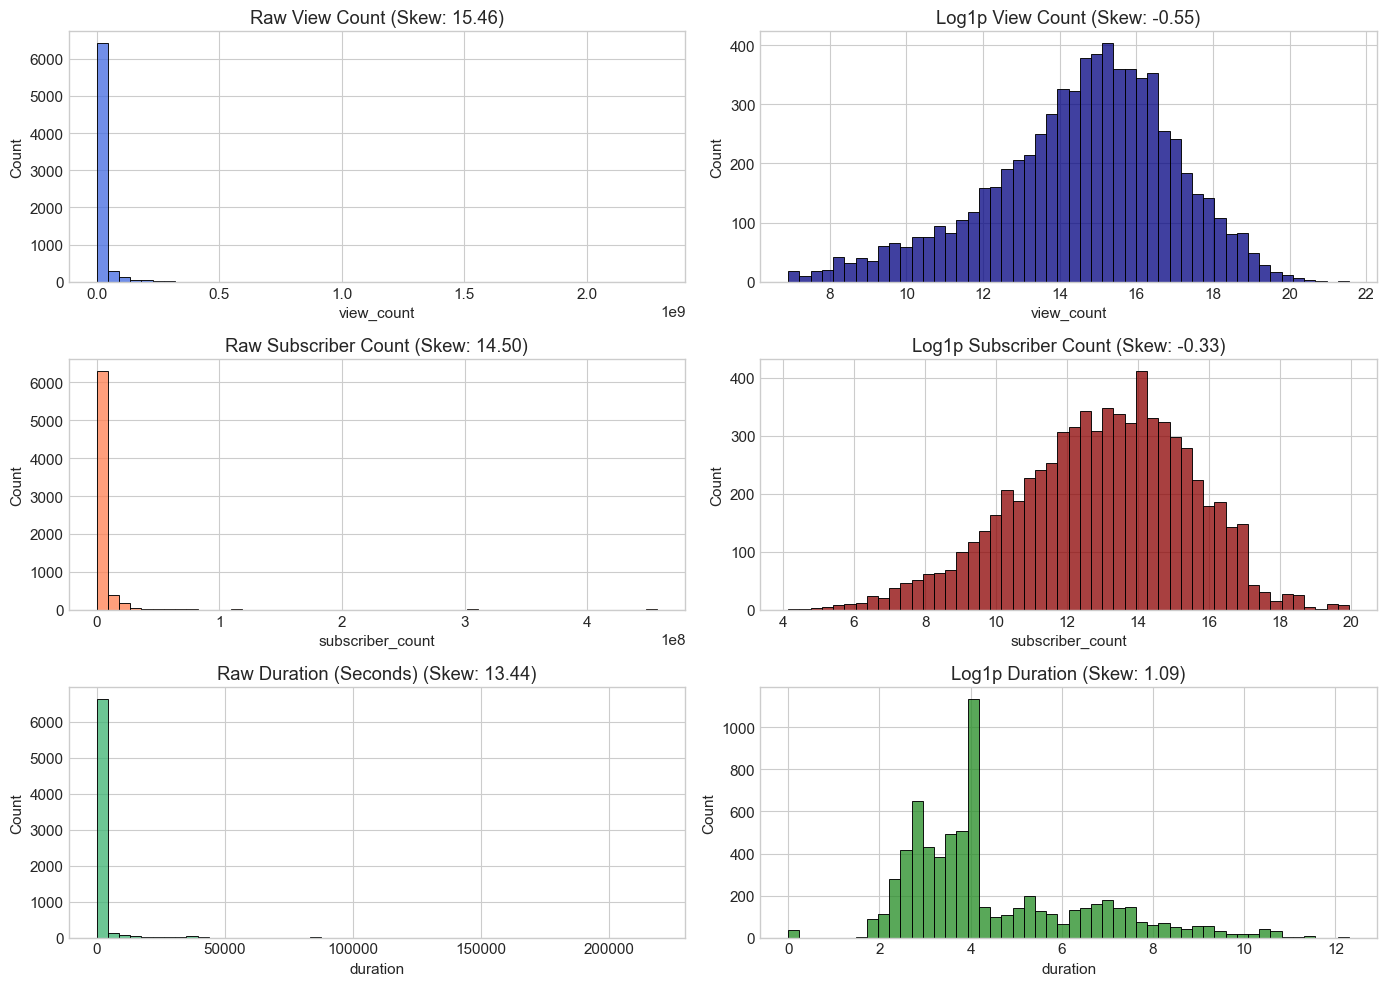

In [11]:
fig, axes = plt.subplots(3, 2, figsize=(14, 10))

# View count
sns.histplot(train_df['view_count'], bins=50, ax=axes[0, 0], color='royalblue')
axes[0, 0].set_title(f"Raw View Count (Skew: {train_df['view_count'].skew():.2f})")
sns.histplot(np.log1p(train_df['view_count']), bins=50, ax=axes[0, 1], color='navy')
axes[0, 1].set_title(f"Log1p View Count (Skew: {np.log1p(train_df['view_count']).skew():.2f})")

# Subscriber count
sns.histplot(train_df['subscriber_count'], bins=50, ax=axes[1, 0], color='coral')
axes[1, 0].set_title(f"Raw Subscriber Count (Skew: {train_df['subscriber_count'].skew():.2f})")
sns.histplot(np.log1p(train_df['subscriber_count']), bins=50, ax=axes[1, 1], color='darkred')
axes[1, 1].set_title(f"Log1p Subscriber Count (Skew: {np.log1p(train_df['subscriber_count']).skew():.2f})")

# Duration
sns.histplot(train_df['duration'], bins=50, ax=axes[2, 0], color='mediumseagreen')
axes[2, 0].set_title(f"Raw Duration (Seconds) (Skew: {train_df['duration'].skew():.2f})")
sns.histplot(np.log1p(train_df['duration']), bins=50, ax=axes[2, 1], color='forestgreen')
axes[2, 1].set_title(f"Log1p Duration (Skew: {np.log1p(train_df['duration']).skew():.2f})")

plt.tight_layout()
plt.show()


### Duration Analysis: YouTube Shorts vs Long-Form
Over 60% of videos in both splits have `duration <= 60` seconds (YouTube Shorts).
Notice also that 38 rows in train and 12 rows in test have `duration == 0`.

In [13]:
train_shorts_pct = (train_df['duration'] <= 60).mean() * 100
test_shorts_pct = (test_df['duration'] <= 60).mean() * 100
train_zero_dur = (train_df['duration'] == 0).sum()
test_zero_dur = (test_df['duration'] == 0).sum()

print(f"Train Shorts (<= 60s): {train_shorts_pct:.2f}%")
print(f"Test Shorts (<= 60s):  {test_shorts_pct:.2f}%")
print(f"Train Duration == 0:    {train_zero_dur} rows")
print(f"Test Duration == 0:     {test_zero_dur} rows")

print("\nSample Train rows with Duration == 0:")
display(train_df[train_df['duration'] == 0][['video_id', 'title', 'view_count', 'subscriber_count', 'virality_score']].head(5))


Train Shorts (<= 60s): 62.89%
Test Shorts (<= 60s):  62.67%
Train Duration == 0:    38 rows
Test Duration == 0:     12 rows

Sample Train rows with Duration == 0:
        video_id  ... virality_score
116  IYMW38-MEow  ...      -2.014411
710  v53vsyP2qIQ  ...      -7.485529
735  G_iPpNnpWhM  ...       2.380357
828  2RSPpsYBiUQ  ...       0.792219
953  XSXEaikz0Bc  ...      -3.426050

[5 rows x 5 columns]


## 4. Temporal Dynamics (`published_at`)
We parse `published_at` to extract upload hour, weekday, and year, which will be transformed into cyclical features (`sin/cos`) in Phase 4.

Train Date Range: 2009-02-16 02:28:11+00:00 to 2025-12-26 18:11:55+00:00
Test Date Range:  2009-06-16 22:48:54+00:00 to 2025-12-26 17:47:51+00:00


<ipython-input-1-f4a26f412650>:25: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.show()


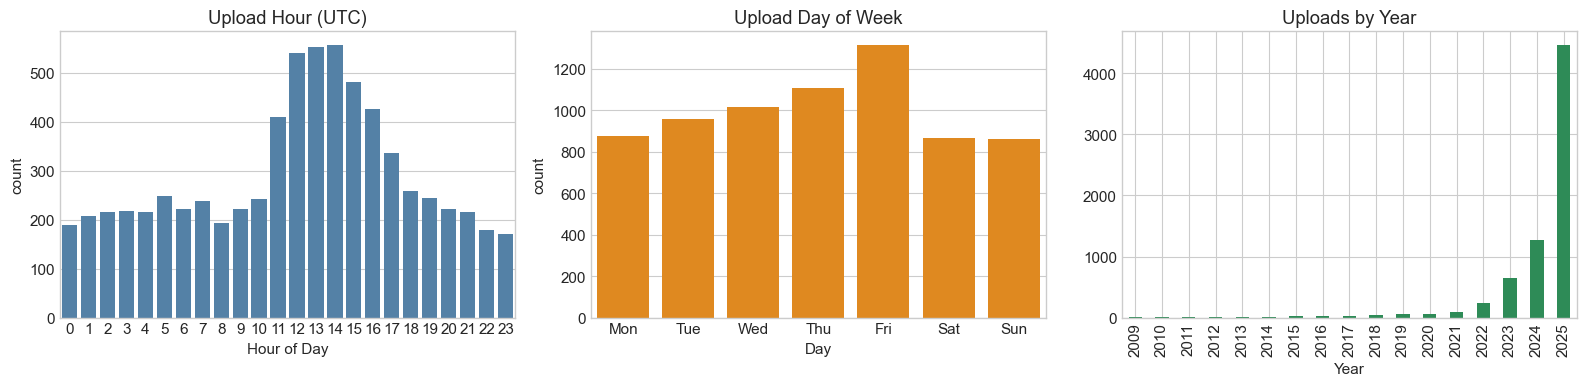

In [15]:
train_df['dt'] = pd.to_datetime(train_df['published_at'])
test_df['dt'] = pd.to_datetime(test_df['published_at'])

train_df['upload_hour'] = train_df['dt'].dt.hour
train_df['upload_weekday'] = train_df['dt'].dt.weekday
train_df['upload_year'] = train_df['dt'].dt.year

fig, axes = plt.subplots(1, 3, figsize=(16, 4))
sns.countplot(x=train_df['upload_hour'], ax=axes[0], color='steelblue')
axes[0].set_title("Upload Hour (UTC)")
axes[0].set_xlabel("Hour of Day")

weekday_labels = ['Mon', 'Tue', 'Wed', 'Thu', 'Fri', 'Sat', 'Sun']
sns.countplot(x=train_df['upload_weekday'], ax=axes[1], color='darkorange')
axes[1].set_title("Upload Day of Week")
axes[1].set_xticks(range(7))
axes[1].set_xticklabels(weekday_labels)
axes[1].set_xlabel("Day")

train_df['upload_year'].value_counts().sort_index().plot(kind='bar', ax=axes[2], color='seagreen')
axes[2].set_title("Uploads by Year")
axes[2].set_xlabel("Year")

plt.tight_layout()
plt.show()

print(f"Train Date Range: {train_df['dt'].min()} to {train_df['dt'].max()}")
print(f"Test Date Range:  {test_df['dt'].min()} to {test_df['dt'].max()}")


## 5. Text & Multilingual Analysis
We examine title character lengths, token expectations, and the presence of emojis and non-ASCII scripts.

Train Titles containing Emojis / Non-ASCII: 44.33%
Test Titles containing Emojis / Non-ASCII:  45.06%
Title Character Length: min=2, median=63.0, max=100
Title Word Count:       min=1, median=10.0, max=26


<ipython-input-1-244a78d5db3a>:21: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.show()


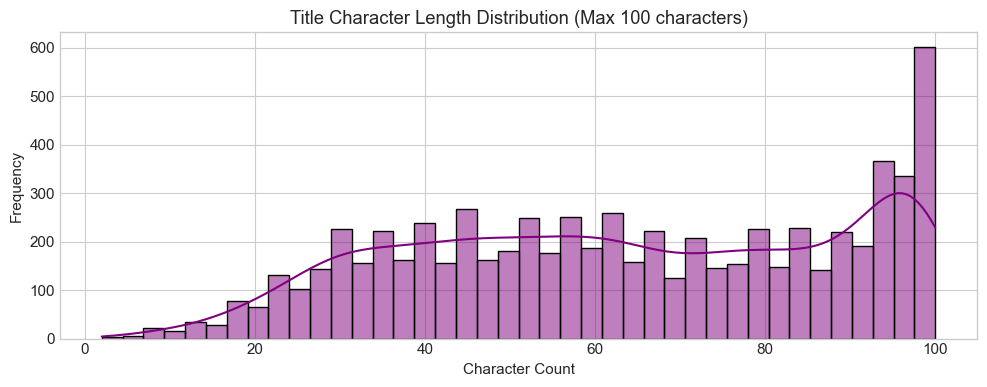

In [17]:
def has_emoji_or_non_ascii(text):
    return any(ord(c) > 127 for c in str(text))

train_non_ascii = train_df['title'].apply(has_emoji_or_non_ascii).mean() * 100
test_non_ascii = test_df['title'].apply(has_emoji_or_non_ascii).mean() * 100

train_title_len = train_df['title'].str.len()
train_word_len = train_df['title'].str.split().str.len()

print(f"Train Titles containing Emojis / Non-ASCII: {train_non_ascii:.2f}%")
print(f"Test Titles containing Emojis / Non-ASCII:  {test_non_ascii:.2f}%")
print(f"Title Character Length: min={train_title_len.min()}, median={train_title_len.median()}, max={train_title_len.max()}")
print(f"Title Word Count:       min={train_word_len.min()}, median={train_word_len.median()}, max={train_word_len.max()}")

plt.figure(figsize=(10, 4))
sns.histplot(train_title_len, bins=40, color='purple', kde=True)
plt.title("Title Character Length Distribution (Max 100 characters)")
plt.xlabel("Character Count")
plt.ylabel("Frequency")
plt.tight_layout()
plt.show()


## 6. Thumbnail URLs & Host Audit

In [19]:
train_domains = train_df['thumbnail_url'].apply(lambda u: urlparse(u).netloc).value_counts()
test_domains = test_df['thumbnail_url'].apply(lambda u: urlparse(u).netloc).value_counts()

print("Train Thumbnail Domains:")
print(train_domains)
print("\nTest Thumbnail Domains:")
print(test_domains)
assert (train_domains.index == ['i.ytimg.com']).all(), "Unexpected domains in train!"
assert (test_domains.index == ['i.ytimg.com']).all(), "Unexpected domains in test!"
print("\nAll 10,014 thumbnail URLs point directly to Google's CDN (i.ytimg.com).")


Train Thumbnail Domains:
thumbnail_url
i.ytimg.com    7000
Name: count, dtype: int64

Test Thumbnail Domains:
thumbnail_url
i.ytimg.com    3014
Name: count, dtype: int64

All 10,014 thumbnail URLs point directly to Google's CDN (i.ytimg.com).


## 7. Channel Leakage Prevention Strategy
Because no explicit `channel_id` is provided in the dataset, videos from the same channel share the exact same `subscriber_count` value.
A standard random split would place videos from the same creator into both train and validation sets, leaking channel baseline appeal and inflating validation scores.
Therefore, `GroupShuffleSplit` grouped by `subscriber_count` will be used in Phase 4.

In [21]:
train_channels = train_df['subscriber_count'].nunique()
test_channels = test_df['subscriber_count'].nunique()
overlap_channels = len(set(train_df['subscriber_count']).intersection(set(test_df['subscriber_count'])))

print(f"Unique subscriber_count values in Train: {train_channels} (across {len(train_df)} rows)")
print(f"Unique subscriber_count values in Test:  {test_channels} (across {len(test_df)} rows)")
print(f"Overlapping subscriber counts between Train and Test: {overlap_channels}")


Unique subscriber_count values in Train: 2445 (across 7000 rows)
Unique subscriber_count values in Test:  1616 (across 3014 rows)
Overlapping subscriber counts between Train and Test: 1221


## 8. Data Quality Summary & Cleaning Decisions

### Cleaning Rules Audit for `train.csv`:
- **Null or negative `view_count`**: **0 rows** detected.
- **Null `subscriber_count`**: **0 rows** detected.
- **Empty or whitespace-only titles**: **0 rows** detected.
- **Unparseable timestamps**: **0 rows** detected.
- **Disagreement with Virality Score formula**: **0 rows** detected (exact match to $\approx 10^{-15}$).

### Observed Edge Cases & Design Decisions:
1. **Duration == 0 (38 train, 12 test rows)**:
   - In production and YouTube API feeds, zero duration can represent livestreams, premiere placeholders, or metadata lags.
   - For modeling: $\ln(\text{duration} + 1)$ safely evaluates to $0.0$ when duration is $0$. Clamping or treating $\text{is\_short} = 1$ handles this without dropping test rows.
2. **Extreme Positive Outliers**:
   - `duration` reaches up to $219,013$ seconds (~60.8 hours). Applying $\ln(\text{duration} + 1)$ compresses this skew from $13.44$ down to $1.09$.
3. **Multilingual Content (~45%)**:
   - Titles contain emojis, Cyrillic, Hindi, Japanese, and accented characters. The `distilbert-base-multilingual-cased` tokenizer will retain these semantics rather than stripping them.
